OPTIMAL TRAFFIC SIGNAL TIMINGS
--------------------------------
Road 1: 9.97 seconds
Road 2: 9.65 seconds
Road 3: 90.37 seconds
Road 4: 10.00 seconds
--------------------------------
Best Fitness: 7.819648747342169e-05


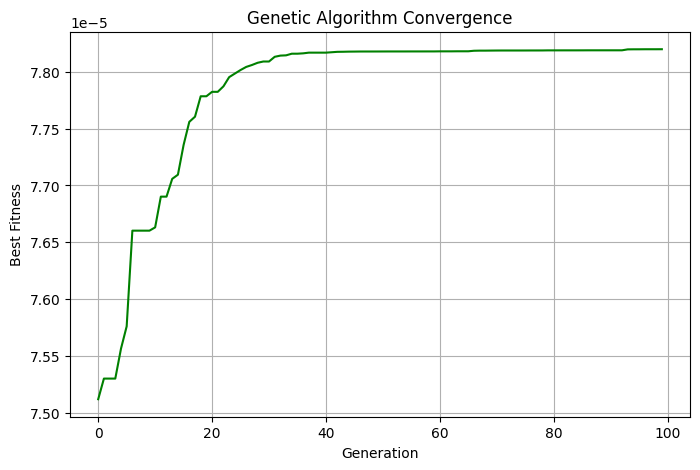

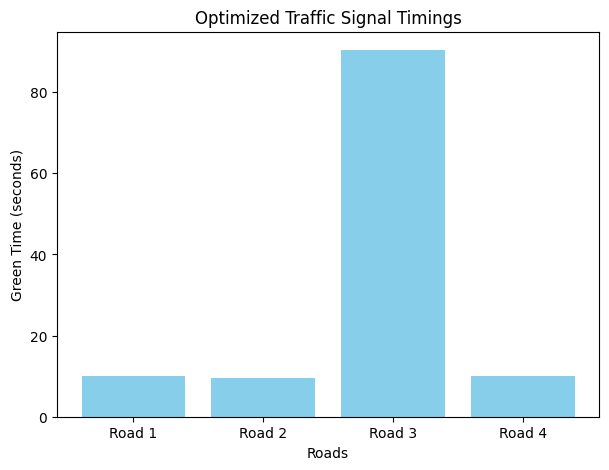

In [6]:

# Genetic Algorithm for Traffic Signal Timing Optimization


import numpy as np
import random
import matplotlib.pyplot as plt

# 1. Traffic conditions for four roads
# Number of vehicles waiting at each road
traffic_density = [40, 25, 60, 35]

# Minimum and maximum green signal time (seconds)
MIN_GREEN = 10
MAX_GREEN = 90

# Total green time available per cycle
TOTAL_TIME = 120

# 2. Generate initial population
POPULATION_SIZE = 50
GENERATIONS = 100
MUTATION_RATE = 0.1

def generate_individual():
    times = np.random.randint(
        MIN_GREEN, MAX_GREEN + 1, 4
    )
    return adjust_times(times)

def adjust_times(times):
    times = np.array(times, dtype=float)

    # Scale timings to total cycle time
    times = times / np.sum(times) * TOTAL_TIME

    return times

# 3. Fitness function
# Lower waiting time gives higher fitness

def fitness(individual):
    waiting_time = 0

    for i in range(4):
        green_time = individual[i]
        vehicles = traffic_density[i]

        # Estimated waiting cost
        waiting_time += vehicles * (TOTAL_TIME - green_time)

    return 1 / (waiting_time + 1)

# 4. Selection
def selection(population):
    selected = random.sample(population, 2)
    return max(selected, key=fitness)

# 5. Crossover
def crossover(parent1, parent2):
    point = random.randint(1, 3)

    child = np.concatenate((
        parent1[:point],
        parent2[point:]
    ))

    return adjust_times(child)

# 6. Mutation
def mutation(individual):
    if random.random() < MUTATION_RATE:
        index = random.randint(0, 3)

        individual[index] += random.uniform(-10, 10)

        individual = np.clip(
            individual, MIN_GREEN, MAX_GREEN
        )

        individual = adjust_times(individual)

    return individual

# 7. Initialize population
population = [
    generate_individual()
    for _ in range(POPULATION_SIZE)
]

best_fitness_history = []

# 8. Genetic Algorithm
for generation in range(GENERATIONS):

    new_population = []

    # Preserve best solution (elitism)
    best = max(population, key=fitness)
    new_population.append(best.copy())

    while len(new_population) < POPULATION_SIZE:

        parent1 = selection(population)
        parent2 = selection(population)

        child = crossover(parent1, parent2)
        child = mutation(child)

        new_population.append(child)

    population = new_population

    best = max(population, key=fitness)
    best_fitness_history.append(fitness(best))

# 9. Display optimal timings
best_solution = max(population, key=fitness)

print("OPTIMAL TRAFFIC SIGNAL TIMINGS")
print("--------------------------------")

roads = ["Road 1", "Road 2", "Road 3", "Road 4"]

for i in range(4):
    print(f"{roads[i]}: {best_solution[i]:.2f} seconds")

print("--------------------------------")
print("Best Fitness:", fitness(best_solution))

# 10. Plot convergence graph
plt.figure(figsize=(8, 5))
plt.plot(best_fitness_history, color="green")
plt.title("Genetic Algorithm Convergence")
plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.grid(True)
plt.show()

# 11. Plot optimized signal timings
plt.figure(figsize=(7, 5))
plt.bar(roads, best_solution, color="skyblue")
plt.title("Optimized Traffic Signal Timings")
plt.xlabel("Roads")
plt.ylabel("Green Time (seconds)")
plt.show()